In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

import tensorflow as tf


In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

In [32]:
df = pd.read_csv("/content/seeds_new (1) - seeds_new (1).csv")

In [33]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [34]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [35]:
df.shape

(210, 8)

In [36]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)'],
      dtype='object')

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [38]:
df.dtypes

,0
Area,float64
Perimeter,float64
Compactness,float64
Length of kernel,float64
Width of kernel,float64
Asymmetry coefficient,float64
Length of kernel groove,float64
"Class (1, 2, 3)",int64


In [39]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [40]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
Perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
Compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
Length of kernel,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
Width of kernel,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
Asymmetry coefficient,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
Length of kernel groove,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500
"Class (1, 2, 3)",210.0,2.000000,0.818448,1.0000,1.00000,2.00000,3.000000,3.0000


In [41]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0


In [42]:
df.duplicated().sum()

np.int64(0)

In [43]:
X = df.drop("Class (1, 2, 3)",axis=1)
y_original = df["Class (1, 2, 3)"]

print("Input shape: ",X.shape)
print("Target shape : ",y_original.shape)

Input shape:  (210, 7)
Target shape :  (210,)


In [44]:
y = y_original - 1

print("Original classes : ",sorted(y_original.unique()))
print("New classes : ",sorted(y.unique()))



Original classes :  [np.int64(1), np.int64(2), np.int64(3)]
New classes :  [np.int64(0), np.int64(1), np.int64(2)]


In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify = y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 168
Testing samples: 42


In [46]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [47]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [48]:
scaler.fit_transform(X_train)

array([[-1.17682401, -1.1750583 , -1.02169157, ..., -1.35751947,
         1.43188942, -0.82441016],
       [-0.87298429, -1.06714618,  0.86676795, ..., -0.59897345,
        -0.3056117 , -1.63150367],
       [-0.12719589,  0.01968295, -0.66917913, ..., -0.40933695,
        -1.4432301 ,  0.1615857 ],
       ...,
       [ 1.83395138,  1.78481679,  0.74506722, ...,  1.5965365 ,
         0.97200114,  1.5846725 ],
       [-0.68998991, -0.62008172, -0.73632435, ..., -0.64170844,
         1.63403093, -0.18605408],
       [-1.25968938, -1.21359834, -1.50010131, ..., -1.47236974,
        -0.10870363, -0.64957378]])

In [49]:
from tensorflow.keras.layers import Input

model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

In [50]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [52]:
loss = "sparse_categorical_crossentropy"

In [53]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, verbose=1, restore_best_weights=True)

In [54]:
history = model.fit(X_train_scaled, y_train, validation_split=0.2, epochs=100, batch_size=16, callbacks=[early_stop])

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 157ms/step - accuracy: 0.3358 - loss: 1.0070 - val_accuracy: 0.5588 - val_loss: 0.9691
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6343 - loss: 0.9392 - val_accuracy: 0.7353 - val_loss: 0.9081
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7090 - loss: 0.8841 - val_accuracy: 0.7353 - val_loss: 0.8536
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7388 - loss: 0.8341 - val_accuracy: 0.7353 - val_loss: 0.8061
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7612 - loss: 0.7899 - val_accuracy: 0.7647 - val_loss: 0.7599
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7612 - loss: 0.7476 - val_accuracy: 0.7647 - val_loss: 0.7120
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7687 - loss: 0.7032 - val_accuracy: 0.8235 - val_loss: 0.6615
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7985 - loss: 0.6575 - val_accuracy: 0.8235 - val_loss

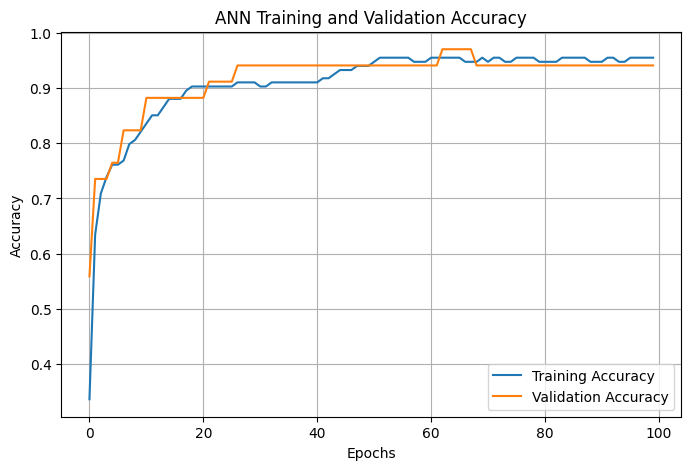

In [55]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'],label='Training Accuracy')
plt.plot(history.history['val_accuracy'],label='Validation Accuracy')
plt.legend()
plt.title("ANN Training and Validation Accuracy")
plt.grid(True)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

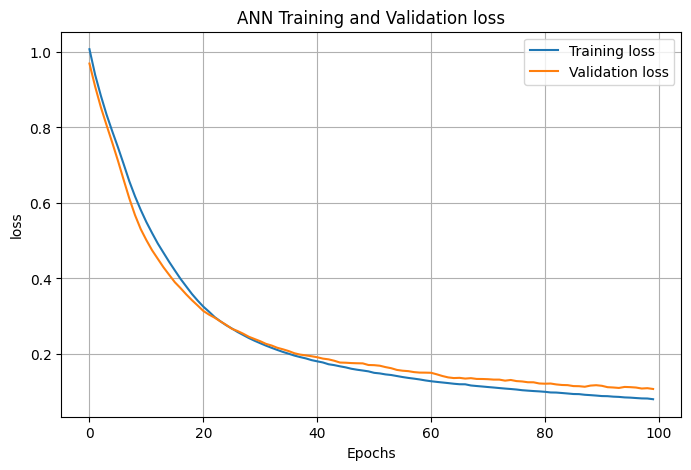

In [56]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.legend()
plt.title("ANN Training and Validation loss")
plt.grid(True)
plt.xlabel("Epochs")
plt.ylabel("loss")
plt.show()

In [57]:
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test,verbose= 1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8571 - loss: 0.3827
Test Loss: 0.3827
Test Accuracy: 0.8571


In [58]:
y_prob = model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
[[9.9540460e-01 3.0387612e-03 1.5566106e-03]
 [9.3143500e-02 2.7844908e-03 9.0407211e-01]
 [3.6674446e-01 6.1355382e-01 1.9701721e-02]
 [3.2379078e-03 2.3377299e-05 9.9673873e-01]
 [1.6162079e-04 9.9983805e-01 3.8029958e-07]]


In [59]:
y_pred = np.argmax(y_prob, axis=1)
print("Predicted encoded classes: ")
print(y_pred[:10])

Predicted encoded classes: 
[0 2 1 2 1 2 1 1 1 1]


In [60]:
y_prob = model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])
y_pred = np.argmax(y_prob, axis=1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
[[9.9540460e-01 3.0387612e-03 1.5566106e-03]
 [9.3143500e-02 2.7844908e-03 9.0407211e-01]
 [3.6674446e-01 6.1355382e-01 1.9701721e-02]
 [3.2379078e-03 2.3377299e-05 9.9673873e-01]
 [1.6162079e-04 9.9983805e-01 3.8029958e-07]]


In [61]:
print("Predicted encoded classes: ")
print(y_pred[:10])

Predicted encoded classes: 
[0 2 1 2 1 2 1 1 1 1]


In [62]:
y_pred_original = y_pred + 1
print("Predicted classes: ")
print(y_pred_original[:10])

Predicted classes: 
[1 3 2 3 2 3 2 2 2 2]


In [63]:
y_test_original = y_test + 1
print("Predicted classes: ")
print(y_test_original[:10])

Predicted classes: 
2      1
167    3
137    2
175    3
130    2
141    3
114    2
51     1
84     2
110    2
Name: Class (1, 2, 3), dtype: int64


In [64]:
comparision = pd.DataFrame({'Actual Classes': y_test_original.values, 'Predicted Classes': y_pred_original})
comparision.head(15)

,Actual Classes,Predicted Classes
0,1,1
1,3,3
2,2,2
3,3,3
4,2,2
5,3,3
6,2,2
7,1,2
8,2,2
9,2,2


In [65]:
accuracy = accuracy_score(y_test_original, y_pred_original)
print("Accuracy: ", accuracy)


Accuracy:  0.8571428571428571


In [66]:
precision = precision_score(y_test_original, y_pred_original, average='weighted')
print("Precision: ", precision)

Precision:  0.8823529411764707


In [67]:
recall = recall_score(y_test_original, y_pred_original, average='weighted')
print("Recall: ", recall)

Recall:  0.8571428571428571


In [68]:
fi =f1_score(y_test_original, y_pred_original, average='weighted')
print("F1-score: ", fi)

F1-score:  0.8445747800586509


In [69]:
metrics = pd.DataFrame({"metric" : ["ACcuracy","Precision","Recall","F1 Score"],
                        "Value" : [accuracy,precision,recall,fi]
                        })
metrics.head()

,metric,Value
0,ACcuracy,0.857143
1,Precision,0.882353
2,Recall,0.857143
3,F1 Score,0.844575


In [70]:
print(classification_report(y_test_original,y_pred_original))

              precision    recall  f1-score   support

           1       1.00      0.57      0.73        14
           2       0.82      1.00      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.88      0.86      0.84        42
weighted avg       0.88      0.86      0.84        42



In [71]:
cm = confusion_matrix(y_test_original, y_pred_original)
print("Confusion Matrix: ")
print(cm)

Confusion Matrix: 
[[ 8  3  3]
 [ 0 14  0]
 [ 0  0 14]]


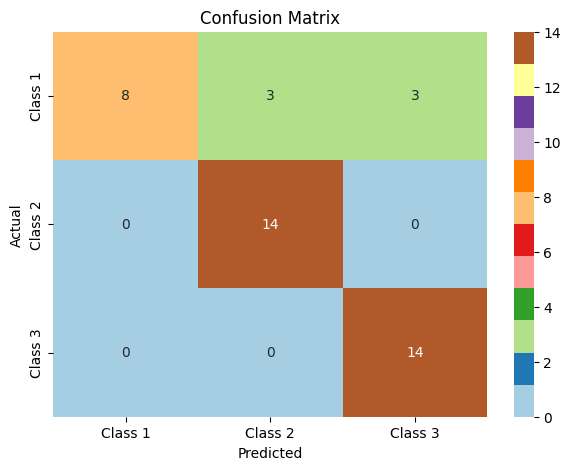

In [72]:
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Paired',xticklabels=["Class 1","Class 2","Class 3"],yticklabels=["Class 1","Class 2","Class 3"])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

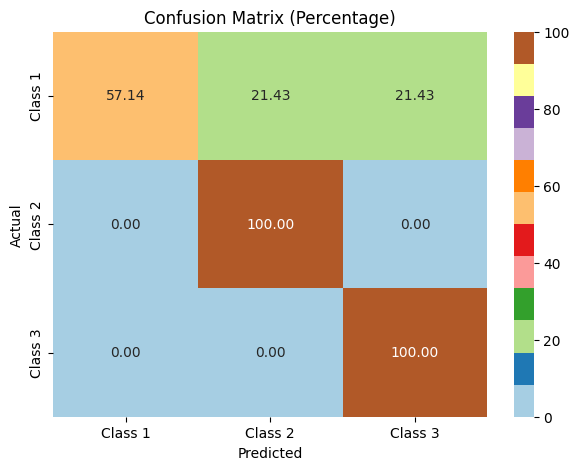

In [73]:
cm_percentage = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]*100
plt.figure(figsize=(7, 5))
sns.heatmap(cm_percentage, annot=True, fmt='.2f', cmap='Paired',xticklabels=["Class 1","Class 2","Class 3"],yticklabels=["Class 1","Class 2","Class 3"])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Percentage)')
plt.show()

In [74]:

def predict_new_seed(area, perimeter, compactness, length, width, asymmetry, groove_length):
    new_seed_data = np.array([[area, perimeter, compactness, length, width, asymmetry, groove_length]])


    new_sample = pd.DataFrame(new_seed_data, columns=[
        'Area', 'Perimeter', 'Compactness',
        'Length of kernel', 'Width of kernel',
        'Asymmetry coefficient', 'Length of kernel groove'
    ])

    new_sample_scaled = scaler.transform(new_sample)
    prediction = model.predict(new_sample_scaled, verbose=0)
    predicted_class = np.argmax(prediction, axis=1)[0]


    print(f"\nPredicted Class: {predicted_class + 1}")


area = float(input("Enter the area of the seed: "))
perimeter = float(input("Enter the perimeter of the seed: "))
compactness = float(input("Enter the compactness of the seed: "))
length = float(input("Enter the length of the seed: "))
width = float(input("Enter the width of the seed: "))
asymmetry = float(input("Enter the asymmetry of the seed: "))
groove_length = float(input("Enter the groove length of the seed: "))

predict_new_seed(
    area,
    perimeter,
    compactness,
    length,
    width,
    asymmetry,
    groove_length
)

Enter the area of the seed: 15.74
Enter the perimeter of the seed: 13.94
Enter the compactness of the seed: 0.888
Enter the length of the seed: 5.009
Enter the width of the seed: 3.337
Enter the asymmetry of the seed: 5.88
Enter the groove length of the seed: 5.001

Predicted Class: 1
